# 07 — Prognoze out-of-sample

**Metodologie** (split cronologic 80% / 20%, pe eșantionul comun activ + exogene optime):

1. **Randamente:** ARMA reestimat pe fereastră extinsă, prognoză one-step-ahead pe tot setul de test → randamente prognozate și reziduuri out-of-sample.
2. **Volatilitate:** GARCH-X / APARCH-X optim (notebookul 06) estimat o singură dată pe train, apoi actualizat recursiv pe test cu reziduurile out-of-sample observate.
3. **Volatilitate realizată** aproximată prin `|reziduu ARMA OOS|` (în %).
4. **Prețuri:** traiectorie obținută prin compunerea randamentelor prognozate, pornind de la ultimul preț din train; intervalele de încredere folosesc varianța zilnică prognozată, cumulată.

Rularea durează (reestimare ARMA la fiecare pas de test).

In [1]:
import sys
import warnings
from pathlib import Path

# Face pachetul `src` importabil indiferent din ce folder se pornește notebookul
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

from src import config, data
from src.forecasting import forecast_asset, price_intervals

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
df = data.load_master_dataset()

## 1. Modelele GARCH-X / APARCH-X optime (din notebookul 06)

Se folosesc modelele cu `Criteriu = AIC minim`.

In [2]:
optime = pd.read_csv(config.GARCHX_OPTIMAL_MODELS)
optime = optime[optime["Criteriu"].str.contains("AIC")]

modele = {
    r.Serie: {
        "nume": r.Model,
        "exog_cols": [r.Exogen_1, r.Exogen_2],
        "tip": "APARCH-X" if "APARCH" in r.Specificatie else "GARCH-X",
        "dist": "t" if "Student" in r.Distributie else "normal",
    }
    for r in optime.itertuples()
}
optime

,Serie,Model,Specificatie,Distributie,Exogen_1,Exogen_2,N_obs,AIC,BIC,Criteriu
0,Rand_BET-NG,BET-NG: Brent + TTF,"APARCH-X(1,1)",Student-t,Rand_Brent,Rand_TTF,1868,4690.555291,4734.816280,AIC minim
1,Rand_H2O,H2O: EUR/RON + USD/RON,"GARCH-X(1,1)",Normală,Rand_EUR,Rand_USD,668,1648.756160,1671.277601,AIC minim
2,Rand_SNN,SNN: Brent + TTF,"GARCH-X(1,1)",Student-t,Rand_Brent,Rand_TTF,1868,5967.159735,6000.355477,AIC minim
3,Rand_SNP,SNP: TTF + EUR/RON,"APARCH-X(1,1)",Student-t,Rand_TTF,Rand_EUR,1868,6102.852282,6147.113271,AIC minim


## 2. Rularea prognozelor

In [3]:
rezultate = {var: forecast_asset(df, var, modele[var]) for var in config.ASSETS if var in modele}
print("Prognoze finalizate pentru:", list(rezultate))

c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency B will be used.
  self._init_dates(dates, freq)
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency B will be used.
  self._init_dates(dates, freq)
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency B will be used.
  self._init_dates(dates, freq)


Rand_SNP: 1868 train | 468 test | SNP: TTF + EUR/RON


c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: Co

    100/468 pași ARMA


c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


...

    100/468 pași ARMA


c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: Co

    200/468 pași ARMA
    300/468 pași ARMA
    400/468 pași ARMA


c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


    468/468 pași ARMA
Prognoze finalizate pentru: ['Rand_SNP', 'Rand_SNN', 'Rand_H2O', 'Rand_BET-NG']


## 3. Metrici

In [4]:
def tabel_metrici(cheie, coloane, cu_model_arima=True):
    rows = []
    for var, res in rezultate.items():
        row = {"Activ": var.replace("Rand_", "")}
        if cu_model_arima:
            row["Model ARIMA"] = f"ARIMA{config.ARMA_ORDERS[var]}"
        row["Model GARCH-X/APARCH-X"] = f"{res['info_model']['tip']}(1,1), {res['info_model']['nume']}"
        row.update({c: res[cheie][c] for c in coloane})
        rows.append(row)
    return pd.DataFrame(rows)


metrici_vol = tabel_metrici("metrici_vol", ["MSE", "RMSE", "MAE"], cu_model_arima=False)
metrici_rand = tabel_metrici("metrici_rand", ["RMSE", "MAE", "MAPE (%)"]).drop(columns="Model GARCH-X/APARCH-X")
metrici_pret = tabel_metrici("metrici_pret", ["RMSE", "MAE", "MAPE (%)"]).drop(columns="Model GARCH-X/APARCH-X")

print("Metrici volatilitate:"); display(metrici_vol.round(6))
print("Metrici randamente:"); display(metrici_rand.round(6))
print("Metrici prețuri:"); display(metrici_pret.round(6))

Metrici volatilitate:


,Activ,Model GARCH-X/APARCH-X,MSE,RMSE,MAE
0,SNP,"APARCH-X(1,1), SNP: TTF + EUR/RON",1.041996,1.020782,0.886794
1,SNN,"GARCH-X(1,1), SNN: Brent + TTF",1.574009,1.254595,1.040121
2,H2O,"GARCH-X(1,1), H2O: EUR/RON + USD/RON",1.849307,1.359892,1.078029
3,BET-NG,"APARCH-X(1,1), BET-NG: Brent + TTF",0.417186,0.645900,0.559333


Metrici randamente:


,Activ,Model ARIMA,RMSE,MAE,MAPE (%)
0,SNP,"ARIMA(2, 0, 1)",0.012648,0.009133,104.448352
1,SNN,"ARIMA(2, 0, 0)",0.016384,0.011326,104.202183
2,H2O,"ARIMA(0, 0, 0)",0.019704,0.013561,99.057289
3,BET-NG,"ARIMA(2, 0, 0)",0.007877,0.004896,144.153323


Metrici prețuri:


,Activ,Model ARIMA,RMSE,MAE,MAPE (%)
0,SNP,"ARIMA(2, 0, 1)",0.154523,0.117342,11.627602
1,SNN,"ARIMA(2, 0, 0)",5.284917,4.154379,7.888342
2,H2O,"ARIMA(0, 0, 0)",22.771264,18.385198,10.225296
3,BET-NG,"ARIMA(2, 0, 0)",424.134471,349.573996,18.492414


## 4. Grafic: volatilitate reală vs. prognozată

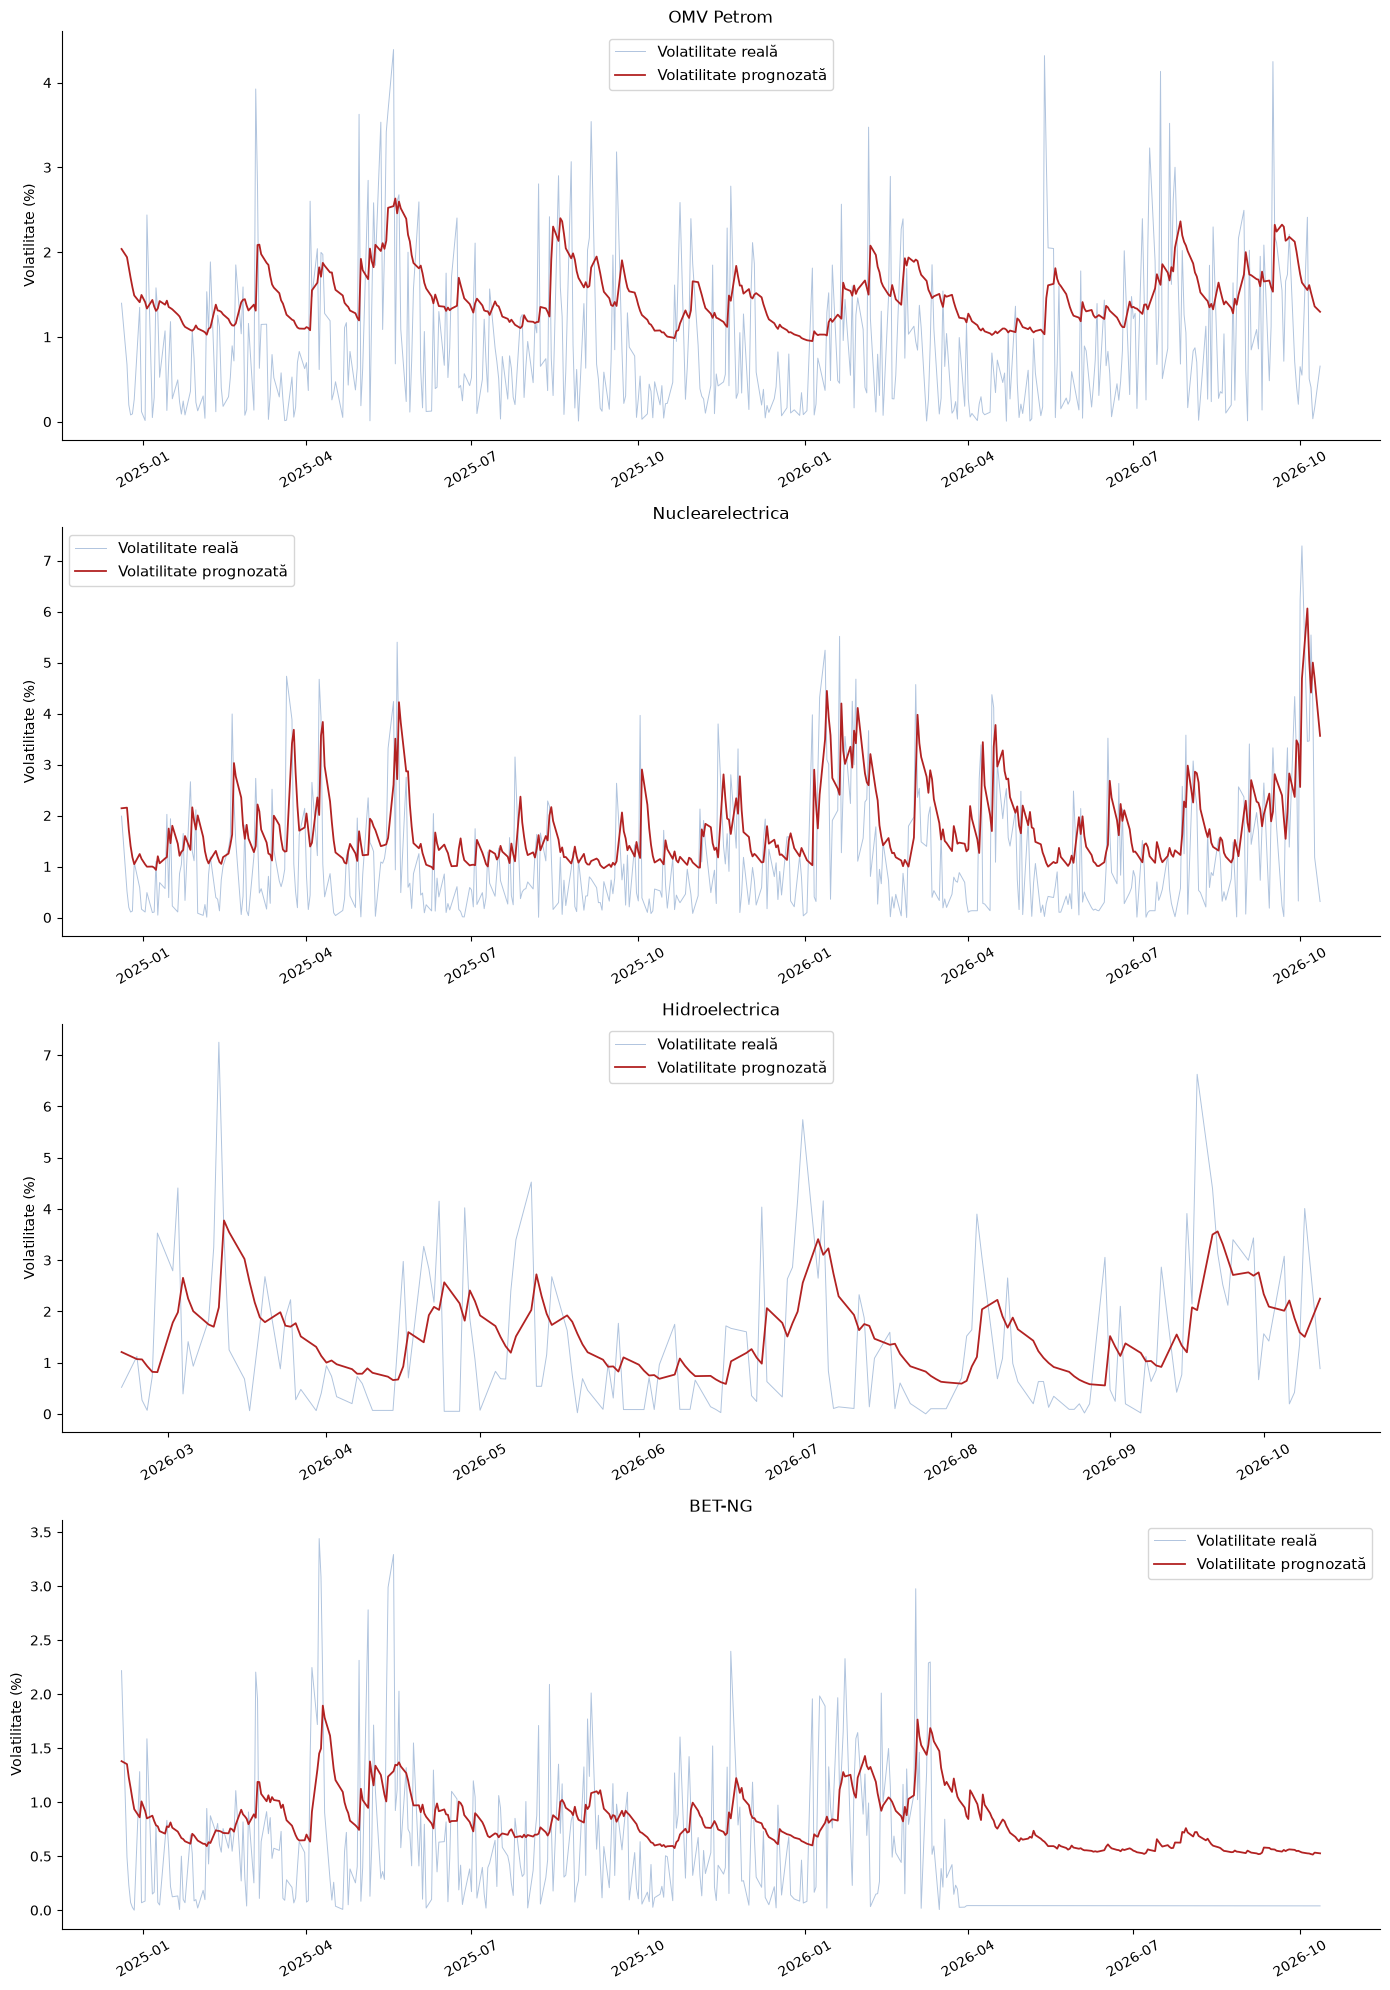

In [5]:
fig, axes = plt.subplots(len(rezultate), 1, figsize=(14, 5 * len(rezultate)))
for ax, (var, res) in zip(np.atleast_1d(axes), rezultate.items()):
    rez = res["rezultate"]
    ax.plot(rez.index, rez["Volatilitate_Realizata"], color="lightsteelblue", linewidth=0.7, label="Volatilitate reală")
    ax.plot(rez.index, rez["Volatilitate_Prognozata"], color="firebrick", linewidth=1.3, label="Volatilitate prognozată")
    ax.set_title(config.ASSET_NAMES[var])
    ax.set_ylabel("Volatilitate (%)")
    ax.legend(fontsize=11)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(config.FIG_DIR / "forecast_volatility.png", dpi=300, bbox_inches="tight")

## 5. Grafic: prețuri prognozate cu intervale de încredere

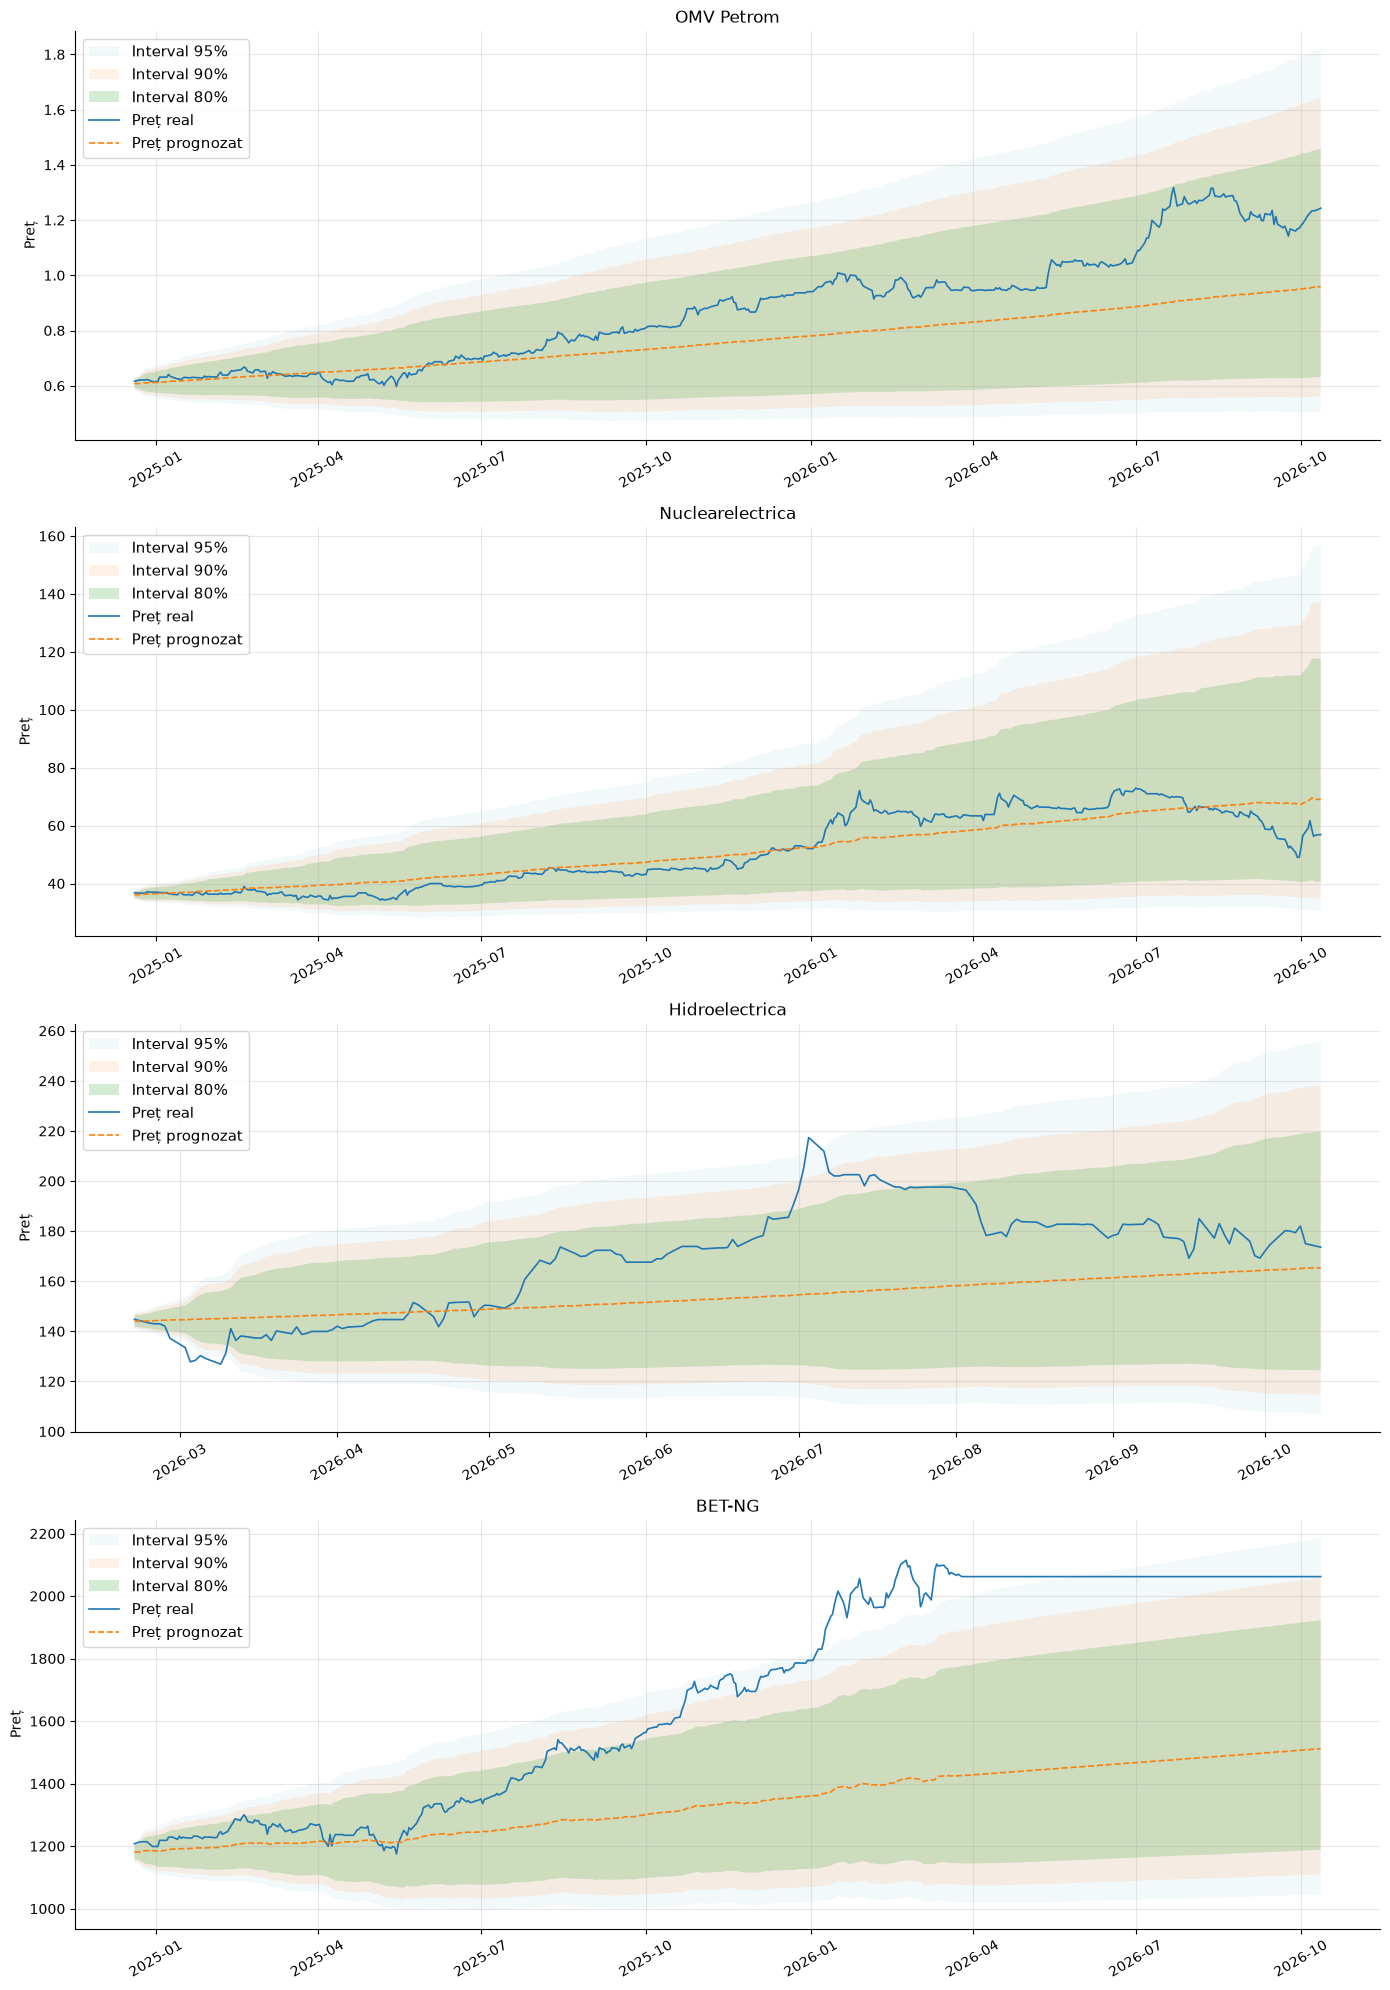

In [6]:
fig, axes = plt.subplots(len(rezultate), 1, figsize=(14, 5 * len(rezultate)))
for ax, (var, res) in zip(np.atleast_1d(axes), rezultate.items()):
    rez = res["rezultate"]
    intervale = price_intervals(rez)
    for nivel, alpha in [("95", 0.05), ("90", 0.10), ("80", 0.20)]:
        lo, up = intervale[nivel]
        ax.fill_between(rez.index, lo.values, up.values, alpha=alpha, label=f"Interval {nivel}%")
    ax.plot(rez.index, rez["Pret_Real"], linewidth=1.2, label="Preț real")
    ax.plot(rez.index, rez["Pret_Prognozat"], linewidth=1.2, linestyle="--", label="Preț prognozat")
    ax.set_title(config.ASSET_NAMES[var])
    ax.set_ylabel("Preț")
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(config.FIG_DIR / "forecast_prices_intervals.png", dpi=300, bbox_inches="tight")

## 6. Export

In [7]:
enc = "utf-8-sig"
T = config.TABLE_DIR
metrici_vol.to_csv(T / "forecast_metrics_volatility.csv", index=False, encoding=enc)
metrici_rand.to_csv(T / "forecast_metrics_returns.csv", index=False, encoding=enc)
metrici_pret.to_csv(T / "forecast_metrics_prices.csv", index=False, encoding=enc)
for var, res in rezultate.items():
    res["rezultate"].to_csv(T / f"forecast_series_{var.replace('Rand_', '')}.csv", encoding=enc)